### 2장 5강: 벡터DB 저장

**학습 목표**

- PostgreSQL과 pgvector 확장의 동작 원리를 이해하고 벡터 저장소의 역할을 설명할 수 있다.
- Docker를 활용해 pgvector 컨테이너를 구동하고 DBeaver에서 확장을 활성화할 수 있다.
- LangChain의 PGVector 인터페이스를 통해 문서 청크와 임베딩을 DB에 저장(Upsert)할 수 있다.

vector database 
- 대용량 벡터 데이터를 안전하게 보관하고 관리 가능

In [1]:
import os
from dotenv import load_dotenv
from langchain_openai import OpenAIEmbeddings
from langchain_postgres.vectorstores import PGVector

load_dotenv()

embedding_model = OpenAIEmbeddings(
    model="text-embedding-3-small"
)

connection_url = os.getenv("DATABASE_URL")

vector_store = PGVector(
    embeddings=embedding_model,
    connection=connection_url,
    collection_name="library_rules",
    use_jsonb=True # metadata를 JSONB로 저장한다
    
)

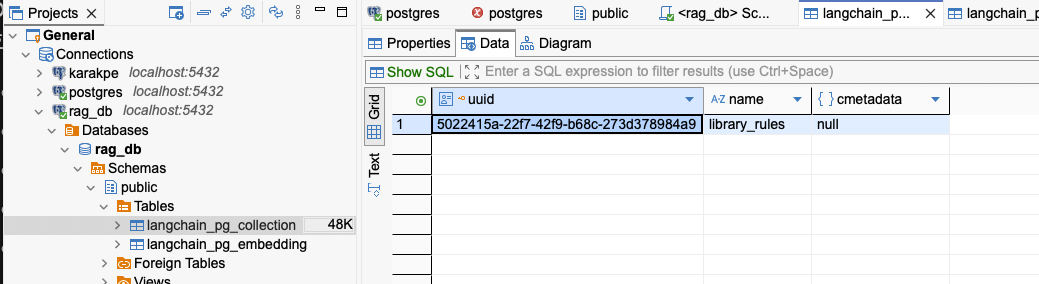

- 위 코드 셀 실행 후 테이블 생성 확인

In [2]:
library_rule_chunks = [
    "[2026학년도 중앙도서관 대출 및 열람 규정]\n제1조(대출자격) 본교 재학생 및 휴학생은 학생증을 제시한 후 도서를 대출할 수 있습니다.",
    "제2조(대출 권수 및 기간) 학부생은 1인당 최대 5권까지 대출할 수 있으며 대출 기간은 14일입니다.\n단, 학술 연구용 특수 도서는 7일간 대출 가능하며 연장은 불가능합니다.",
    "제3조(연체 및 제재) 반납 기한을 초과할 경우 연체 일수만큼 대출이 정지됩니다."
]
# 지금은 메타데이터 존재 x
# 텍스트만 chunking해서 가져온 상태

saved_ids = vector_store.add_texts(
    texts=library_rule_chunks,
) # 추가되면 테이블의 id컬럼은 UUID값으로 자동 생성됨

print(f"현재 저장 갯수: {len(saved_ids)}개")
print(f"청크 ID: {saved_ids}")

현재 저장 갯수: 3개
청크 ID: ['7c5d7ddb-9782-41be-a24c-de7d8c3d30ec', '09c4c70f-6d05-4079-be5b-b5f5361698bd', '03888aeb-64b2-4528-a621-66b796db3ff6']


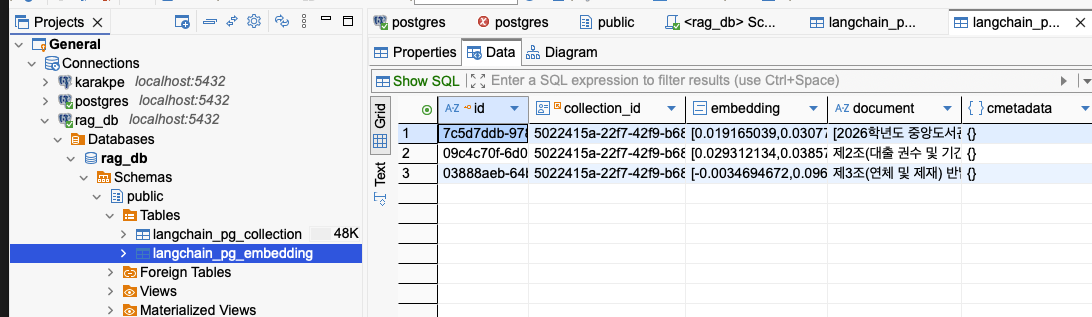

- `langchain_pg_embedding` 테이블에 청킹 텍스트 3개 들어감 확인
- 그러나 id 정의를 빼먹고 저장하면 같은 데이터가 중복이 되어 DB에 저장됨

In [4]:
# id 를 직접 지정하여 중복 데이터 저장 방지

chunk_ids = ["rule_chunk_001", "rule_chunk_002", "rule_chunk_003"]

saved_ids_not_duplicated = vector_store.add_texts(
    texts=library_rule_chunks,
    ids=chunk_ids
) 

print(f"현재 저장 갯수: {len(saved_ids_not_duplicated)}개")
print(f"청크 ID: {saved_ids_not_duplicated}")

현재 저장 갯수: 3개
청크 ID: ['rule_chunk_001', 'rule_chunk_002', 'rule_chunk_003']


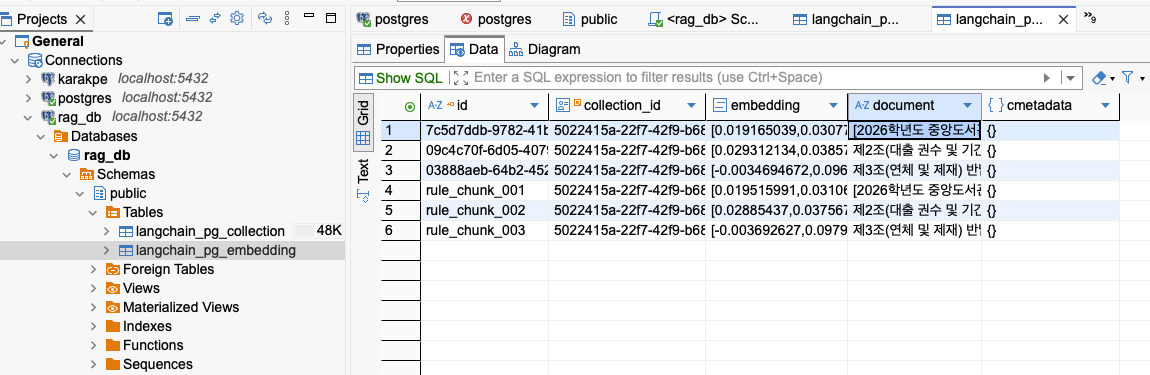

- id를 지정해서 저장하면 위 코드를 중복 실행해도 중복 데이터가 들어가지 않음


#### 벡터 유사도 검색 실행
similarity_search: 사용자 질의를 실시간으로 임베딩한 후, DB 내 벡터 컬럼과의 거리를 계산해 최적의 문서를 추출합니다.

In [15]:
question = "특수 도서는 며칠 동안 대출할 수 있나요?"

search_results = vector_store.similarity_search(
    query=question,
    k=1 # Top-k 설정: 유사도 높은 순서대로 가져오기
)

print(search_results)
print(search_results[0].page_content)

[Document(id='rule_chunk_002', metadata={}, page_content='제2조(대출 권수 및 기간) 학부생은 1인당 최대 5권까지 대출할 수 있으며 대출 기간은 14일입니다.\n단, 학술 연구용 특수 도서는 7일간 대출 가능하며 연장은 불가능합니다.')]
제2조(대출 권수 및 기간) 학부생은 1인당 최대 5권까지 대출할 수 있으며 대출 기간은 14일입니다.
단, 학술 연구용 특수 도서는 7일간 대출 가능하며 연장은 불가능합니다.


- score도 기록

In [13]:
search_results2 = vector_store.similarity_search_with_score(
    query=question,
    k=3
)

for chunk, score in search_results2:
    print(f"score={score:.4f} / {chunk.page_content}") # 스코어가 작을수록 정답

score=0.4439 / 제2조(대출 권수 및 기간) 학부생은 1인당 최대 5권까지 대출할 수 있으며 대출 기간은 14일입니다.
단, 학술 연구용 특수 도서는 7일간 대출 가능하며 연장은 불가능합니다.
score=0.5774 / [2026학년도 중앙도서관 대출 및 열람 규정]
제1조(대출자격) 본교 재학생 및 휴학생은 학생증을 제시한 후 도서를 대출할 수 있습니다.
score=0.7499 / 제3조(연체 및 제재) 반납 기한을 초과할 경우 연체 일수만큼 대출이 정지됩니다.
